In [18]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
loan_df = pd.read_csv("Loan_default.csv")
loan_df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [17]:
loan_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  Default         25534

In [35]:
loan_df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [4]:
loan_df.dtypes

LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

In [13]:
# make data dictionary
col_descriptions = {
    "LoanID": "Unique identifier for each loan",
    "Age": "Borrower's age in years",
    "Income": "Borrower's annual income",
    "LoanAmount": "Amount of money borrowed",
    "CreditScore": "Borrower's credit score",
    "MonthsEmployed": "Months the borrower has been employed",
    "NumCreditLines": "Number of open credit lines",
    "InterestRate": "Loan interest rate (%)",
    "LoanTerm": "Loan length in months",
    "DTIRatio": "Debt-to-income ratio",
    "Education": "Highest education level",
    "EmploymentType": "Employment status (full-time, part-time, self-employed, unemployed)",
    "MaritalStatus": "Marital status",
    "HasMortgage": "Whether the borrower has a mortgage (Yes/No)",
    "HasDependents": "Whether the borrower has dependents (Yes/No)",
    "LoanPurpose": "Reason for the loan (home, auto, education, business, other)",
    "HasCoSigner": "Whether the loan has a co-signer (Yes/No)",
    "Default": "Target variable: 1 = defaulted, 0 = did not default",
}

data_dictionary = pd.DataFrame({
    "Column": loan_df.columns,
    "Data Type": loan_df.dtypes.astype(str).values,
    "Missing (#)": loan_df.isna().sum().values,
    "Unique (#)": loan_df.nunique().values,
    "What it means": loan_df.columns.map(col_descriptions),
})

data_dictionary

,Column,Data Type,Missing (#),Unique (#),What it means
0,LoanID,str,0,255347,Unique identifier for each loan
1,Age,int64,0,52,Borrower's age in years
2,Income,int64,0,114620,Borrower's annual income
3,LoanAmount,int64,0,158729,Amount of money borrowed
4,CreditScore,int64,0,550,Borrower's credit score
5,MonthsEmployed,int64,0,120,Months the borrower has been employed
6,NumCreditLines,int64,0,4,Number of open credit lines
7,InterestRate,float64,0,2301,Loan interest rate (%)
8,LoanTerm,int64,0,5,Loan length in months
9,DTIRatio,float64,0,81,Debt-to-income ratio


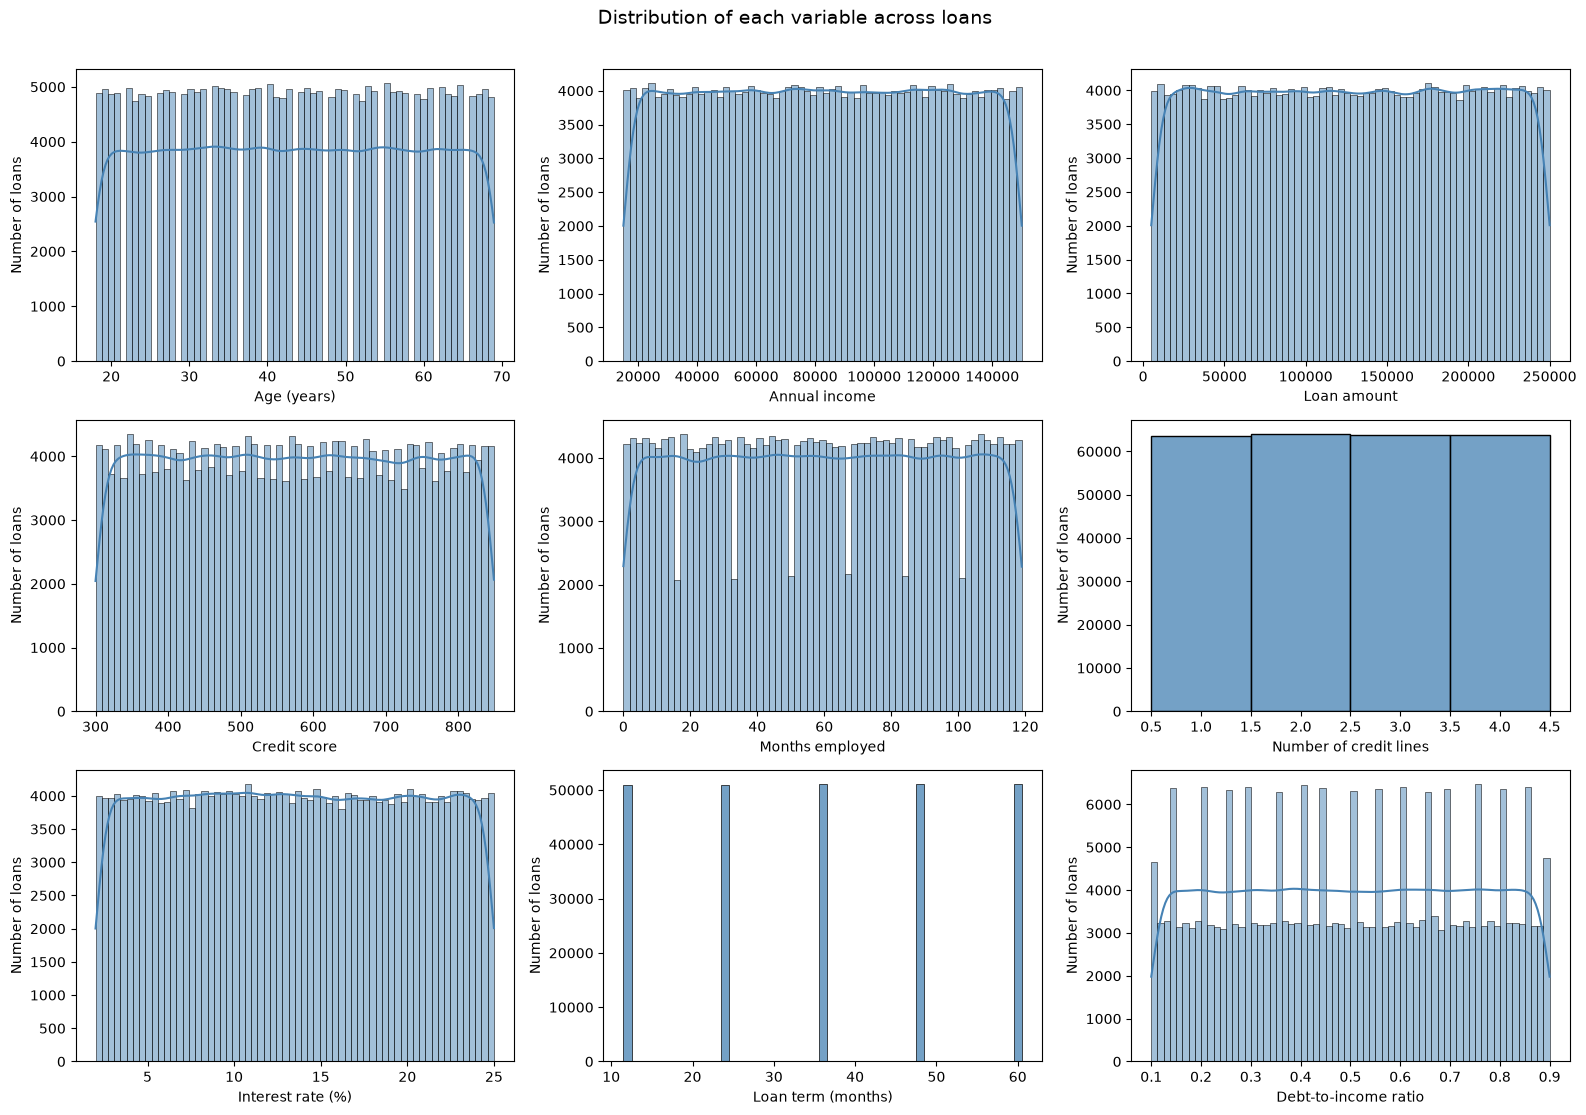

Age               0.0
Income           -0.0
LoanAmount       -0.0
CreditScore       0.0
MonthsEmployed   -0.0
NumCreditLines   -0.0
InterestRate      0.0
LoanTerm         -0.0
DTIRatio         -0.0
Name: skewness, dtype: float64


In [20]:
# looking at variable distributions
num_cols = ["Age", "Income", "LoanAmount", "CreditScore", "MonthsEmployed",
            "NumCreditLines", "InterestRate", "LoanTerm", "DTIRatio"]

labels = {
    "Age": "Age (years)", "Income": "Annual income", "LoanAmount": "Loan amount",
    "CreditScore": "Credit score", "MonthsEmployed": "Months employed",
    "NumCreditLines": "Number of credit lines", "InterestRate": "Interest rate (%)",
    "LoanTerm": "Loan term (months)", "DTIRatio": "Debt-to-income ratio",
}
discrete = {"NumCreditLines", "LoanTerm"}

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flat, num_cols):
    is_discrete = col in discrete
    sns.histplot(loan_df[col], kde=not is_discrete, discrete=is_discrete,
                 ax=ax, color="steelblue")
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Number of loans")
fig.suptitle("Distribution of each variable across loans", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

print(loan_df[num_cols].skew().round(2).rename("skewness"))

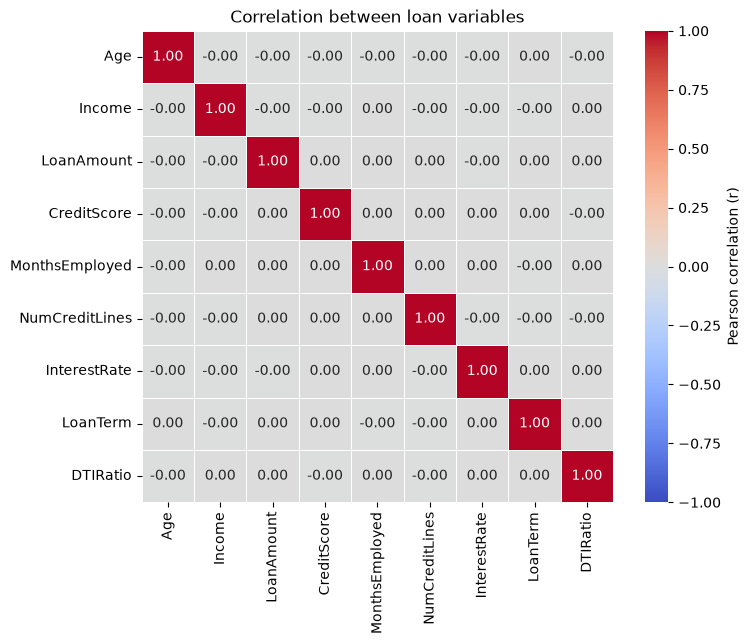

In [21]:
# looking at correlations between variables
corr = loan_df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Pearson correlation (r)"})
ax.set_title("Correlation between loan variables")
plt.tight_layout()
plt.show()

          count  percent
Default                 
0        225694     88.0
1         29653     12.0


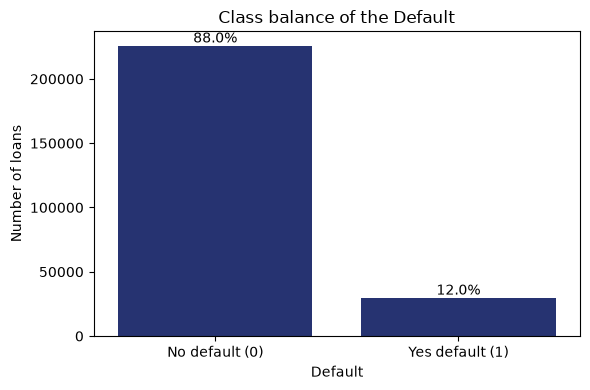

In [34]:
# look at class counts and percentages
counts = loan_df["Default"].value_counts()
pct = loan_df["Default"].value_counts(normalize=True).round(2)
pct = pct*100
print(pd.DataFrame({"count": counts, "percent": pct}))

# bar chart
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="Default", data=loan_df, ax=ax, color="#1a2b7d")
ax.set_xticks([0, 1])
ax.set_xticklabels(["No default (0)", "Yes default (1)"])
ax.set_ylabel("Number of loans")
ax.set_title("Class balance of the Default")
for p, v in zip(ax.patches, pct.sort_index()):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()